In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
units = pd.read_csv('units_L234.csv').copy()

In [5]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

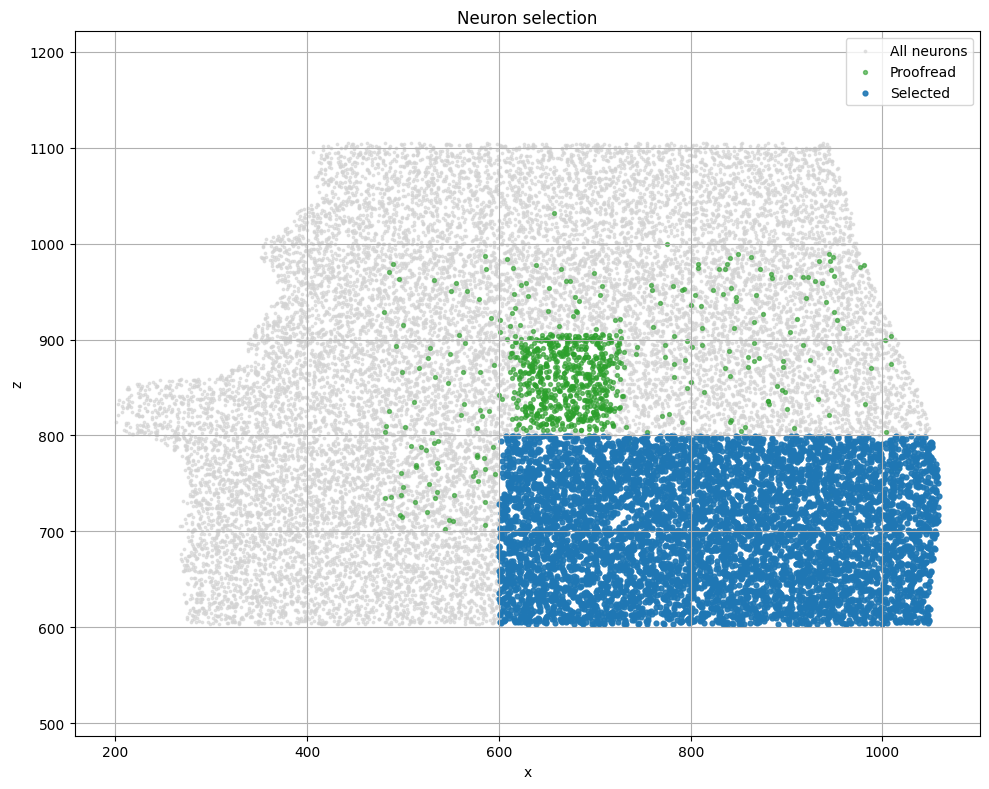

In [6]:
units_cleaned = clean_dataset(units)

selected_mask = (units_cleaned["pt_position_z"] < 800) & (units_cleaned["pt_position_x"] > 600)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    units.loc[selected_mask, "pt_position_x"],
    units.loc[selected_mask, "pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [7]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [8]:
E_L23 = units_cleaned[mask_exc & mask_l23 & selected_mask].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [9]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [10]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [11]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [12]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [13]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [14]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )

    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    pre_pop_indexed = (
    pre_pop
    .drop_duplicates("pt_root_id")
    .set_index("pt_root_id")
    )

    Z = []
    for pt_id in all_ids:
        Z.append(
            pre_pop_indexed.loc[
                pt_id,
                ["pt_position_x", "pt_position_y", "pt_position_z"]
            ].values
        )

    Z = np.asarray(Z, dtype=np.float32)

    Z = (
        Z - Z.mean(axis=0)
    ) / Z.std(axis=0)

    print(all_ids)
    # active_ids_index = active_ids.map(id_map).values



    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    X = df[features].values
    y = df['label'].values

    return X, y, Z, features, pre_idx, post_idx

In [15]:
path, pre, post = pathways[0]
X, y, Z, features, pre_idx, post_idx = build_dataset(pre, post, synapses, metric=['Euclidean'])

71408
11611056
Index([864691134884804602, 864691134885076730, 864691134885518074,
       864691134885576442, 864691134885584634, 864691134885594362,
       864691134885707258, 864691134885761018, 864691134886095610,
       864691134917864458,
       ...
       864691135429385520, 864691137197628225, 864691135980365192,
       864691135725024939, 864691136310655066, 864691135657776514,
       864691136444759171, 864691136091466676, 864691136389610256,
       864691135583278189],
      dtype='int64', length=3408)
metri vaut ['Euclidean']


In [16]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_distance_sanity_check_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 50
PATIENCE = 51
LR = 1e-3
DIMS = [1]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [17]:
# =========================
# Model
# =========================
class EmbeddingModel(nn.Module):
    def __init__(
        self,
        n_neurons,
        Z,
        dim=3,
    ):
        super().__init__()

        self.dim = dim

        Z = torch.as_tensor(Z, dtype=torch.float32)
        self.register_buffer("Z", Z)

        # Exponential decoder parameters
        self.log_A = nn.Parameter(torch.tensor(0.0))
        self.log_C = nn.Parameter(torch.tensor(0.0))
        self.B = nn.Parameter(torch.tensor(0.0))



    def forward_logits(self, pre_idx, post_idx):
        z_pre = self.Z[pre_idx]
        z_post = self.Z[post_idx]

        dist2 = ((z_pre - z_post) ** 2).sum(dim=1) / self.dim

        A = torch.exp(self.log_A)
        C = torch.exp(self.log_C) + 1e-6

        kernel = A * torch.exp(-dist2 / (C ** 2))

        logits = kernel + self.B

        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(
            self.forward_logits(pre_idx, post_idx)
        )

In [18]:
# =========================
# Data
# =========================

_, y, Z, _, pre_idx, post_idx = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

71408
11611056
Index([864691134884804602, 864691134885076730, 864691134885518074,
       864691134885576442, 864691134885584634, 864691134885594362,
       864691134885707258, 864691134885761018, 864691134886095610,
       864691134917864458,
       ...
       864691135429385520, 864691137197628225, 864691135980365192,
       864691135725024939, 864691136310655066, 864691135657776514,
       864691136444759171, 864691136091466676, 864691136389610256,
       864691135583278189],
      dtype='int64', length=3408)
metri vaut ['Euclidean']
n_neurons: 3408
n_pairs: 11611056
positive rate: 0.006150000263005495


In [19]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [20]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [21]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [113]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [114]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, Z=Z, dim=3).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
Resuming dim=1 from checkpoints_embedding_MLP_distance_sanity_check_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple\last_dim_1.pt
Resumed at epoch 11 | best_epoch=2 | best_val_auc=0.7916
dim=01 | epoch=011 | train_loss=0.1138 | val_loss=0.1076 | val_auc=0.7872
dim=01 | epoch=012 | train_loss=0.1018 | val_loss=0.0966 | val_auc=0.7861
dim=01 | epoch=013 | train_loss=0.0917 | val_loss=0.0873 | val_auc=0.7852
dim=01 | epoch=014 | train_loss=0.0831 | val_loss=0.0795 | val_auc=0.7840
dim=01 | epoch=015 | train_loss=0.0759 | val_loss=0.0728 | val_auc=0.7827
dim=01 | epoch=016 | train_loss=0.0697 | val_loss=0.0672 | val_auc=0.7815
dim=01 | epoch=017 | train_loss=0.0645 | val_loss=0.0623 | val_auc=0.7806
dim=01 | epoch=018 | train_loss=0.0600 | val_loss=0.0582 | val_auc=0.7797
dim=01 | epoch=019 | train_loss=0.0562 | val_loss=0.0548 | val_auc=0.7788
dim=01 | epoch=020 | train_loss=0.0530 | val_loss=0.0518 | val_auc=0.7785
dim=01 | epoch=021 | train

In [24]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 15
CHECKPOINT_DIR = "checkpoints_embedding_MLP_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple_paper"

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    Z=Z,
    dim=3
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

df_Z_full = df_Z.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

print(df_Z_full.head())
print(df_Z_full.shape)



AttributeError: module 'torch' has no attribute '_utils'

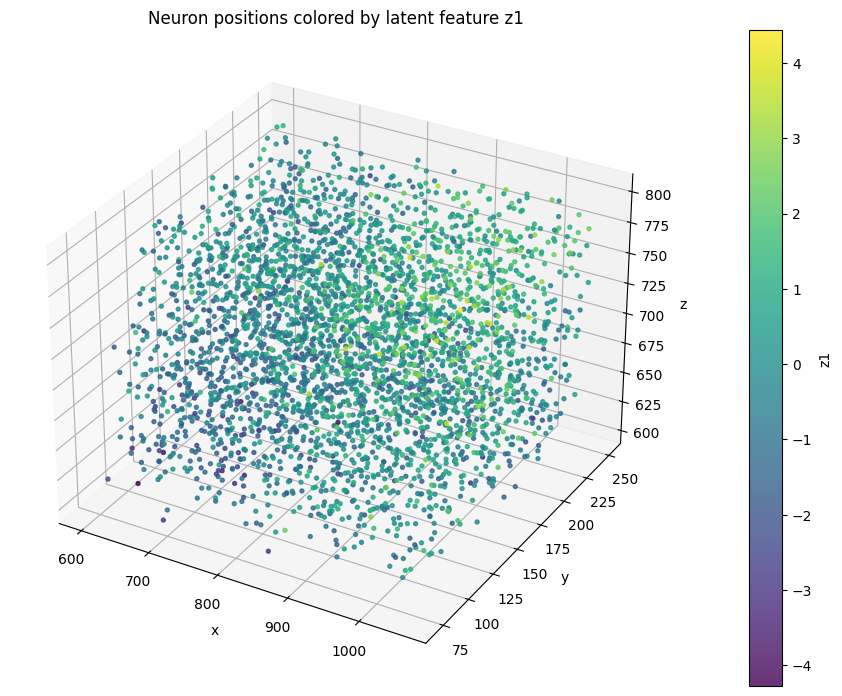

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z2"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


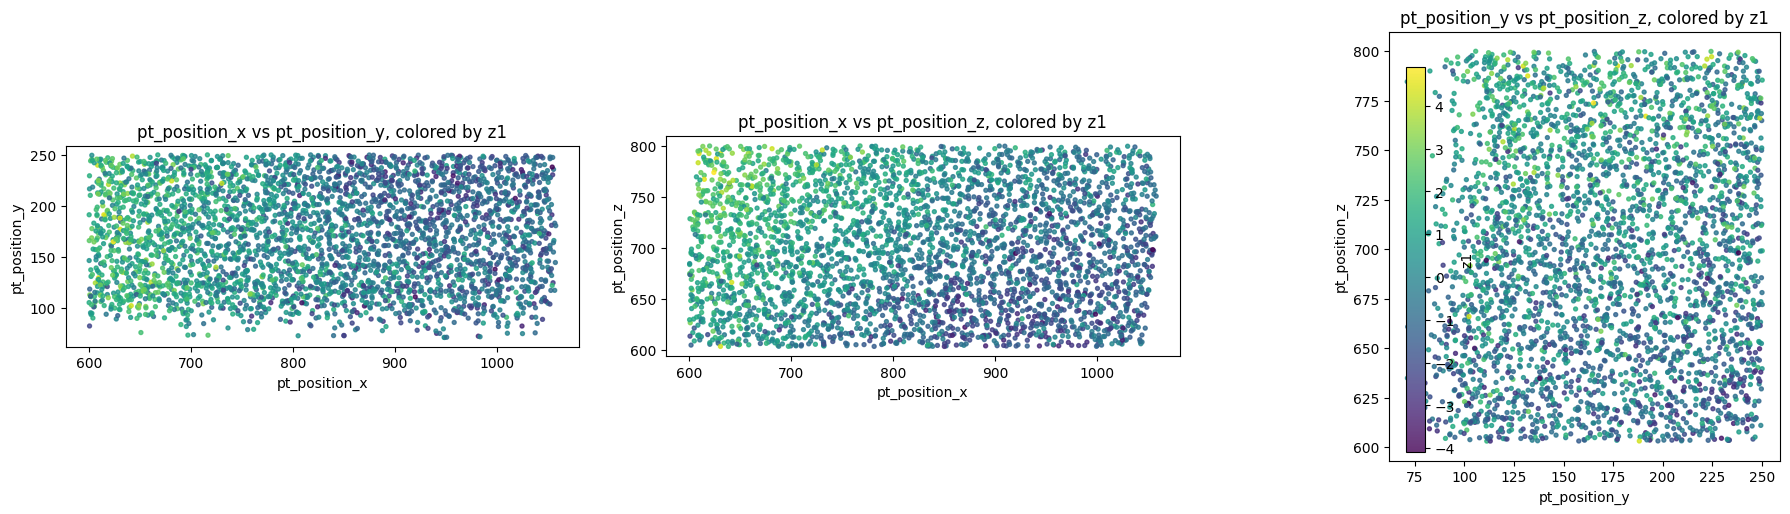

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [ ]:
for coord in ["pt_position_x", "pt_position_y", "pt_position_z"]:
    corr = df_plot["z1"].corr(df_plot[coord])
    print(f"corr(z1, {coord}) = {corr:.3f}")

corr(z1, pt_position_x) = -0.605
corr(z1, pt_position_y) = -0.064
corr(z1, pt_position_z) = 0.371


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Anatomical distances
# =========================

id_to_pos = units_cleaned.set_index("pt_root_id")[
    [
        "pt_position_x",
        "pt_position_y",
        "pt_position_z"
    ]
]

pre_pos = id_to_pos.loc[pre_ids].values
post_pos = id_to_pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

# =========================
# 3. Predict probabilities
# =========================

model.eval()

with torch.no_grad():

    p_pred = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

y_emp = y.cpu().numpy()

# =========================
# 4. Build dataframe
# =========================

df_curve = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "p_pred": p_pred
})

df_curve["bin"] = pd.cut(
    df_curve["distance"],
    bins=40
)

# =========================
# 5. Aggregate
# =========================

curve = (
    df_curve
    .groupby("bin")
    .agg(
        empirical_prob=("y", "mean"),
        predicted_prob=("p_pred", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum")
    )
)

curve["bin_center"] = np.array([
    b.mid for b in curve.index
])

# =========================
# 6. Plot
# =========================

plt.figure(figsize=(8,5))

plt.plot(
    curve["bin_center"],
    curve["empirical_prob"],
    marker="o",
    label="Empirical P(connection)"
)

plt.plot(
    curve["bin_center"],
    curve["predicted_prob"],
    marker="o",
    label="Sanity-check model"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")

plt.title(
    "Sanity-check: P(connection) vs distance"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.show()

NameError: name 'all_ids' is not defined

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:74: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 4
Best val loss: 0.0425


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:184: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:213: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.008

Analyzing dim = 2
Loaded best epoch: 2
Best val loss: 0.0559


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:184: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:213: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


...

corr(geometrical distance, latent distance) = 0.802

Analyzing dim = 14
Loaded best epoch: 48
Best val loss: 0.0326


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:184: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:213: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.781

Analyzing dim = 15
Loaded best epoch: 49
Best val loss: 0.0328


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:184: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_35556\546914547.py:213: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.811


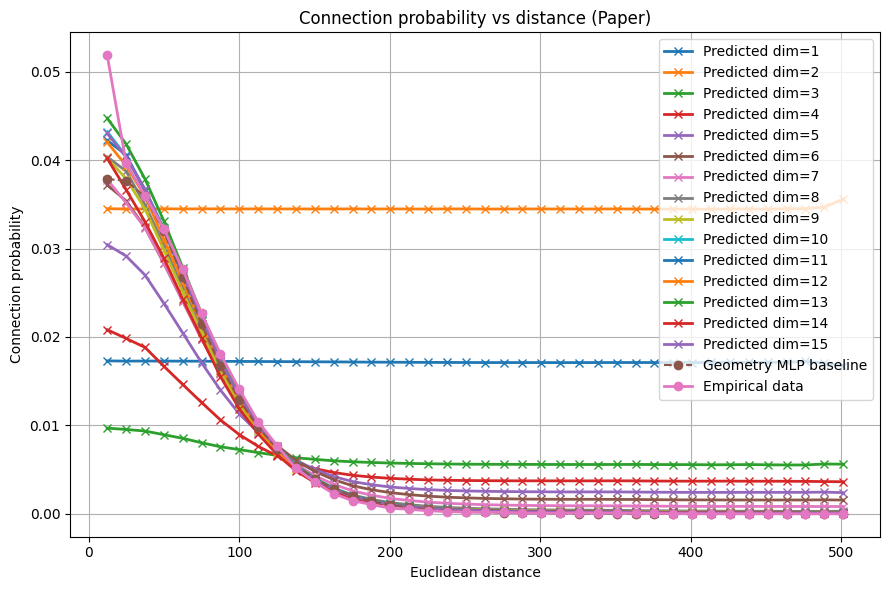

dim=15 corr=0.811


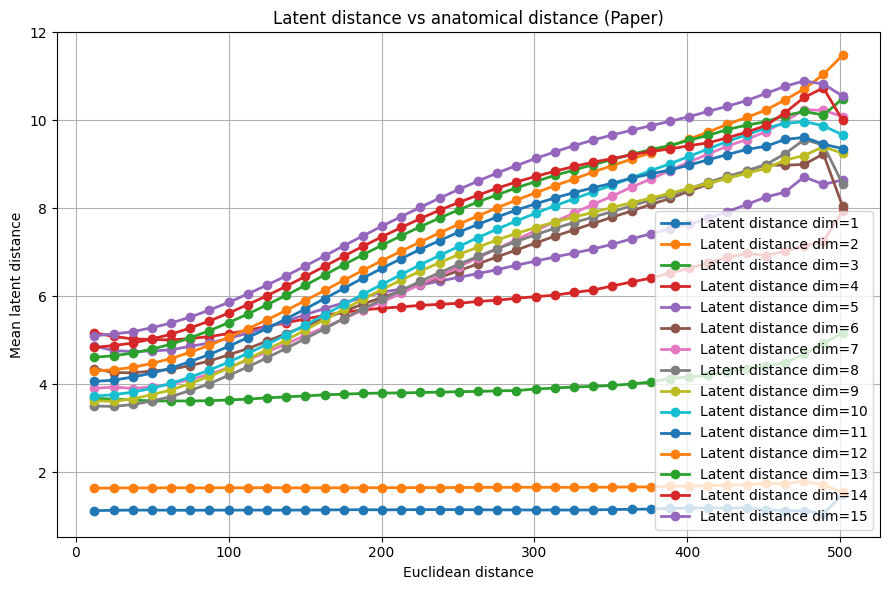

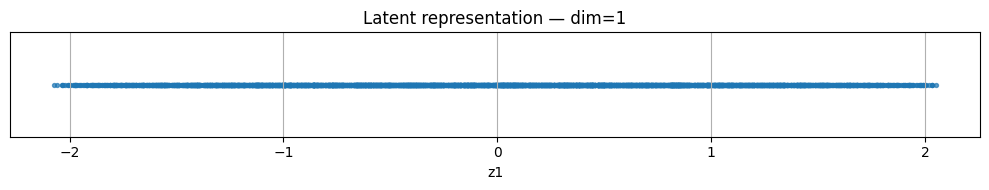

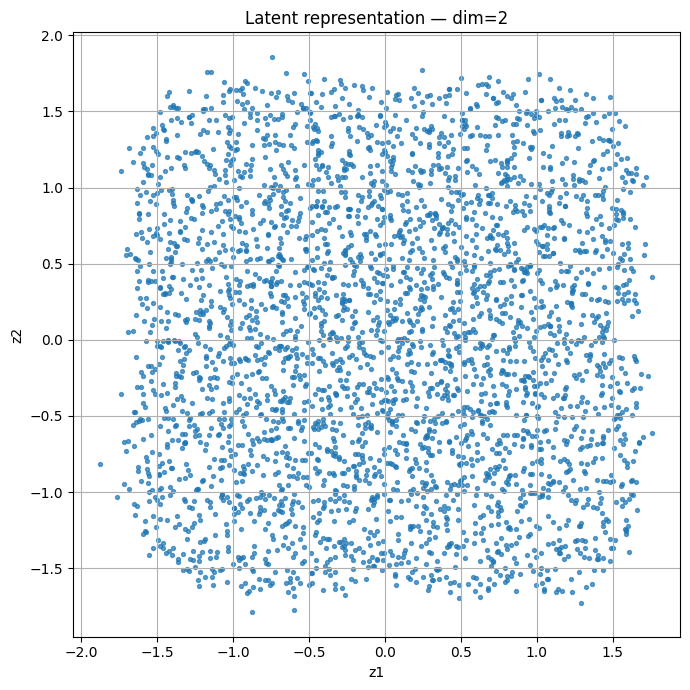

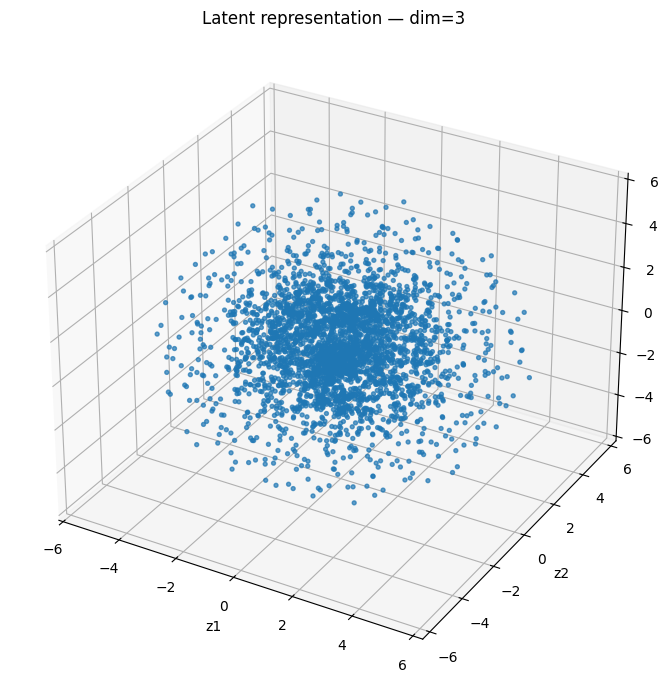

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
N_BINS = 40
BATCH_SIZE = 32768



# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------



    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        linewidth=2,
        marker="x",
        label=f"Predicted dim={dim}"
    )


baseline_curve = pd.read_csv(
        "baselines/geometry_mlp_probability_vs_distance.csv",
        index_col=0
    )

baseline_centers = np.array([
pd.Interval(left=float(s.split(",")[0][1:]),
            right=float(s.split(",")[1][:-1])).mid
for s in baseline_curve.index
])

plt.plot(
    baseline_curve["bin_center"],
    baseline_curve["predicted_prob"],
    marker="o",
    linestyle="--",
    label="Geometry MLP baseline"
)

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (Paper)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="o",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (Paper)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1', 'z2', 'z3', 'z4', 'z5', 'z6', 'z7', 'z8', 'z9', 'z10', 'z11', 'z12', 'z13', 'z14', 'z15']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit']


In [ ]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
     pt_position_x  pt_position_y  pt_position_z  pref_ori_fit
z1       -0.607767      -0.069750       0.362288      0.007356
z2        0.386934      -0.009717       0.386359     -0.073434
z3       -0.053099       0.195073       0.399353     -0.046932
z4       -0.471617      -0.045861      -0.127971      0.031624
z5        0.810294       0.042757       0.192472     -0.101821
z6       -0.044626      -0.406240      -0.213702      0.040130
z7       -0.419607       0.219001      -0.384715      0.109571
z8       -0.478129       0.026061       0.410425     -0.026412
z9        0.723294      -0.003894      -0.105232     -0.036467
z10      -0.467096      -0.081175      -0.364759      0.113245
z11      -0.650382      -0.125101       0.186776      0.048515
z12       0.015409       0.217088      -0.462646      0.074995
z13      -0.603116      -0.015516      -0.263127      0.116389
z14      -0.013731       0.303424      -0.217586      0.062517
z15      -0.701712       0

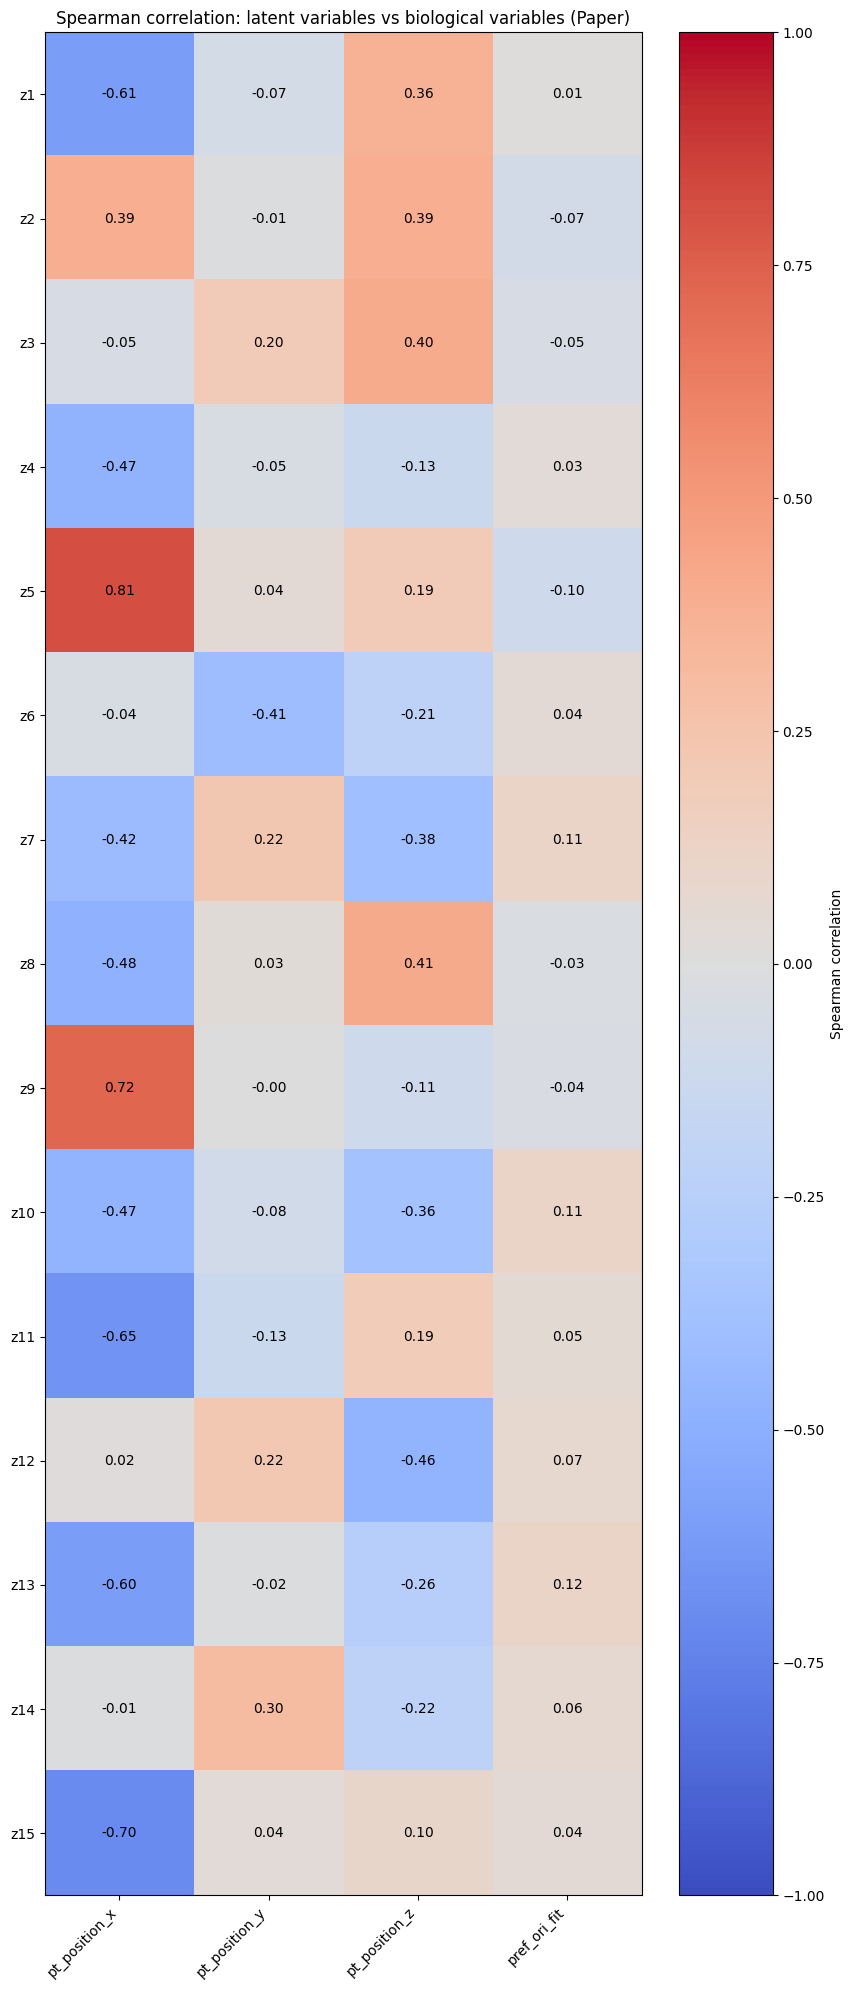

In [ ]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (Paper)")
plt.tight_layout()
plt.show()

=== Strongest correlations ===
z5   pt_position_x    0.810294
z9   pt_position_x    0.723294
z15  pt_position_x    0.701712
z11  pt_position_x    0.650382
z1   pt_position_x    0.607767
z13  pt_position_x    0.603116
dtype: float64


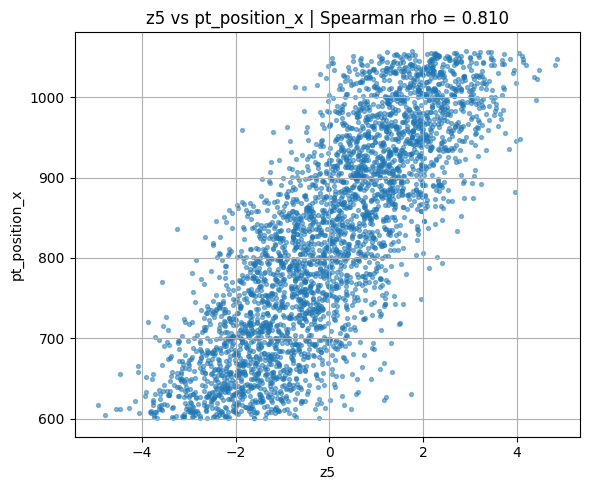

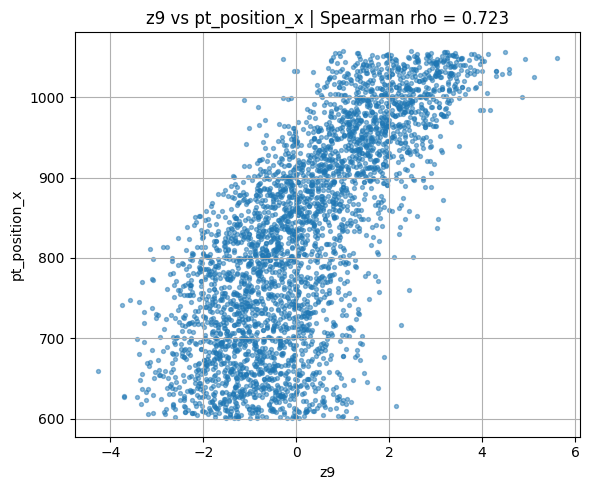

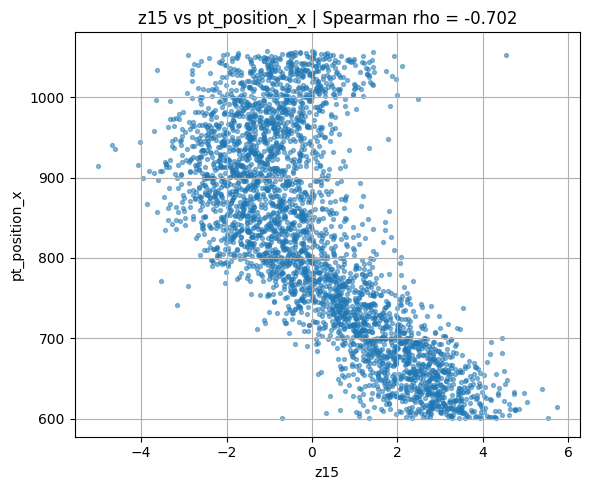

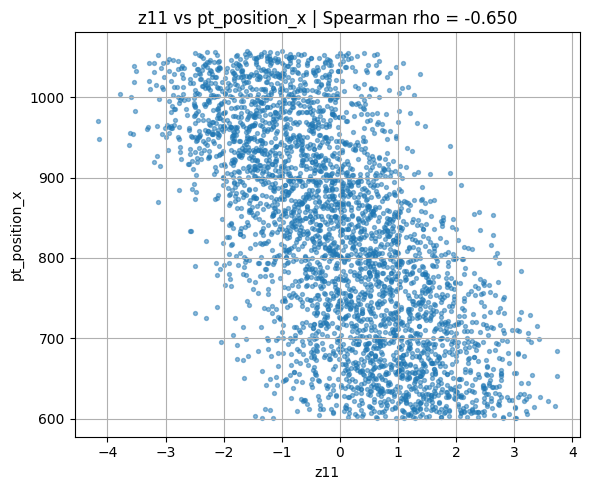

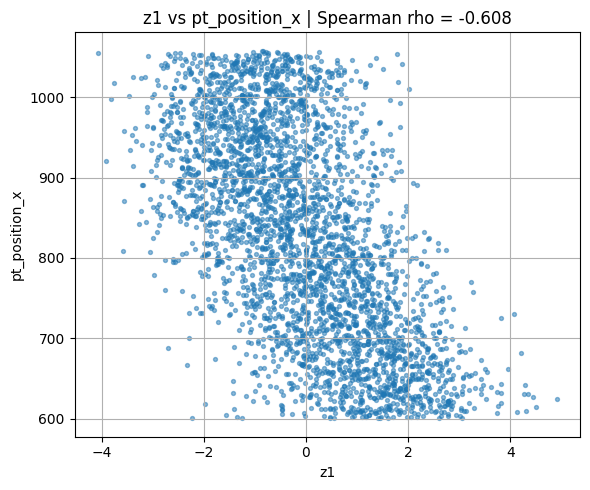

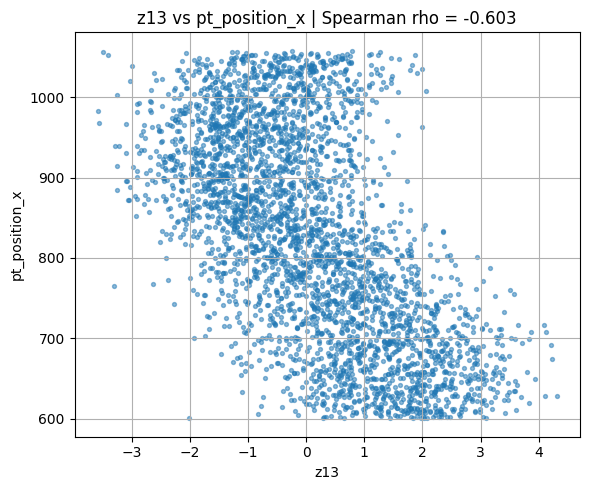

In [ ]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

PCA explained variance: [0.33504406 0.10811935]


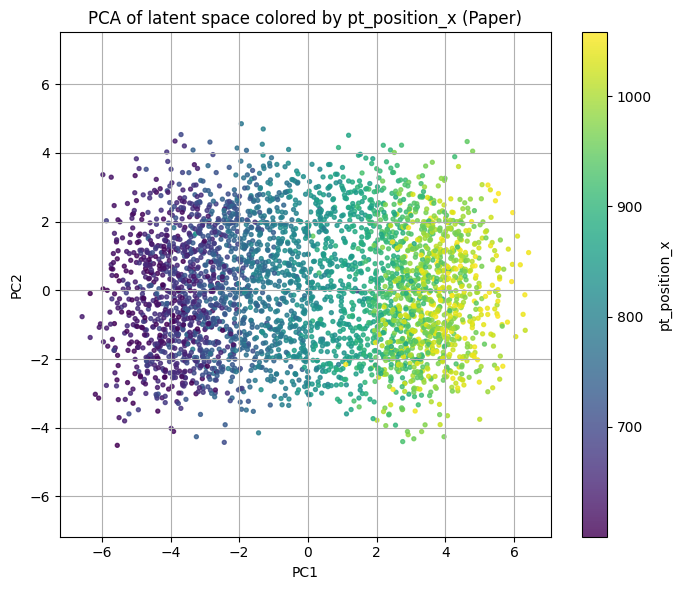

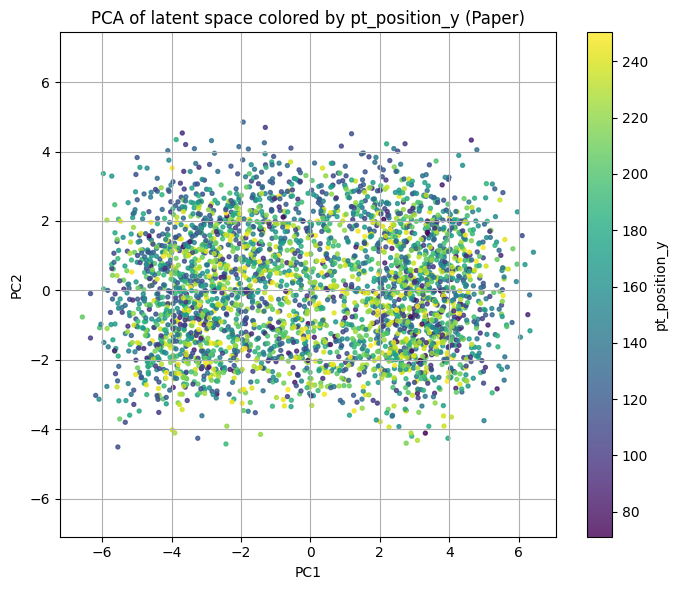

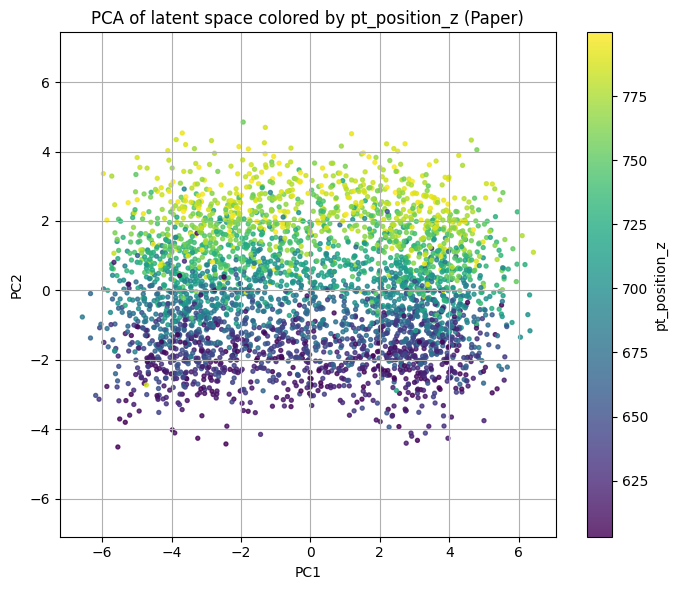

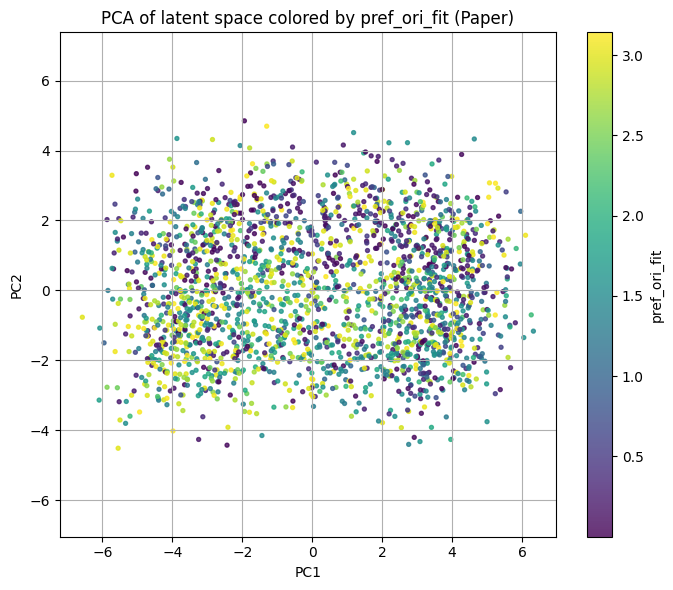

In [ ]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (Paper)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")